In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from Bio import SeqIO

pep_hits_long = pd.read_csv('long_w_fc_before_z_score_102226.csv')


pep_hits = pd.read_csv('pep_hits__after_FC_AG_z_score_102226.csv')

In [3]:
cchfv = pep_hits_long[pep_hits_long['species'] == 'Orthonairovirus haemorrhagiae'].copy()

In [4]:
cchfv.to_csv('cchfv_hits_long.csv')

## importing the reference sequences fetched from UniProt UP000008767

In [5]:
records = list(SeqIO.parse('UP000008767_2026_09_21_CCHFV_reference.fasta', 'fasta'))

for r in records:
    print(r.id, len(r.seq))

sp|P89522|NCAP_CCHFI 482
sp|Q6TQR6|L_CCHFI 3945
sp|Q8JSZ3|GP_CCHFI 1684
sp|P0DTL3|NSS_CCHFI 150


In [6]:
reference_by_protein = {
    "polymerase": str(next(r.seq for r in records if "Q6TQR6" in r.id)),
    "glycoprotein": str(next(r.seq for r in records if "Q8JSZ3" in r.id)),
    "nucleoprotein": str(next(r.seq for r in records if "P89522" in r.id)),
    "NSs": str(next(r.seq for r in records if "P0DTL3" in r.id)),
}

In [7]:
print(cchfv['category'].value_counts())
print(cchfv['sequence'].nunique())
print(cchfv['protein_std'].unique())

category
Household contact    6648
Lassa survivor       2880
US healthy           2088
Name: count, dtype: int64
24
['polymerase' 'glycoprotein' 'nucleoprotein' 'polyprotein']


## import PairwiseAligner and use BLOSUM62 matrix for local protein alignment

In [8]:
from Bio.Align import PairwiseAligner
from Bio.Align import substitution_matrices

aligner = PairwiseAligner()
aligner.mode = 'local' #want the peptide to find its best location within the reference

aligner.substitution_matrix = substitution_matrices.load("BLOSUM62")
aligner.open_gap_score = -10
aligner.extend_gap_score = -0.5

## polymerase

In [9]:
ref = reference_by_protein['glycoprotein']

gp = cchfv[cchfv['protein_std'].eq("glycoprotein")].copy()

unique_gp_peptides = gp['sequence'].drop_duplicates()

In [10]:
ref

'MHISLMYAILCLQLCGLGETHGSHNETRHNKTDTMTTPGDNPSSEPPVSTALSITLDPSTVTPTTPASGLEGSGEVYTSPPITTGSLPLSETTPELPVTTGTDTLSAGDVDPSTQTAGGTSAPTVRTSLPNSPSTPSTPQDTHHPVRNLLSVTSPGPDETSTPSGTGKESSATSSPHPVSNRPPTPPATAQGPTENDSHNATEHPESLTQSATPGLMTSPTQIVHPQSATPITVQDTHPSPTNRSKRNLKMEIILTLSQGLKKYYGKILRLLQLTLEEDTEGLLEWCKRNLGLDCDDTFFQKRIEEFFITGEGHFNEVLQFRTPGTLSTTESTPAGLPTAEPFKSYFAKGFLSIDSGYYSAKCYSGTSNSGLQLINITRHSTRIVDTPGPKITNLKTINCINLKASIFKEHREVEINVLLPQVAVNLSNCHVVIKSHVCDYSLDIDGAVRLPHIYHEGVFIPGTYKIVIDKKNKLNDRCTLFTDCVIKGREVRKGQSVLRQYKTEIRIGKASTGSRRLLSEEPSDDCISRTQLLRTETAEIHGDNYGGPGDKITICNGSTIVDQRLGSELGCYTINRVRSFKLCENSATGKNCEIDSVPVKCRQGYCLRITQEGRGHVKLSRGSEVVLDACDTSCEIMIPKGTGDILVDCSGGQQHFLKDNLIDLGCPKIPLLGKMAIYICRMSNHPKTTMAFLFWFSFGYVITCILCKAIFYLLIIVGTLGKRLKQYRELKPQTCTICETTPVNAIDAEMHDLNCSYNICPYCASRLTSDGLARHVIQCPKRKEKVEETELYLNLERIPWVVRKLLQVSESTGVALKRSSWLIVLLVLFTVSLSPVQSAPIGQGKTIEAYRAREGYTSICLFVLGSILFIVSCLMKGLVDSVGNSFFPGLSICKTCSISSINGFEIESHKCYCSLFCCPYCRHCSTDKEIHKLHLSICKKRKKGSNVMLAVCKLMCFRATMEVSNRALFIRSIINTTFVLCILILAVCVVSTSAVEME

## define mapping function -> sticking to local alignment

In [11]:
def map_peptide_to_reference(peptide, reference, aligner):
    """
    goal: map a peptide onto a reference protein. 

    output: returns a dictionary containing
    - alignment score
    - reference start/end (1-based)
    - reference positions covered by aligned peptide residues
    """

    #if no exact substring match, use local alignment
    alignment = aligner.align(reference, peptide)[0] #[0] to extract the first and best-scoring Alignment object from the results

    #aligner.align[0].aligned returns the start and end coordinates of the aligned segments for the target and query sequences
    ref_blocks, peptide_blocks = alignment.aligned

    ref_positions = []

    for (ref_start, ref_end), (pep_start, pep_end) in zip(ref_blocks, peptide_blocks):
        
        for i in range(ref_end - ref_start):
            ref_positions.append(ref_start + i + 1) #1-based

    #overall peptide coordinates
    pep_start = peptide_blocks[0][0] + 1
    pep_end = peptide_blocks[-1][1] #take the last block,so -1, in case there are more than one aligned blocks. and [1] for the end

    #total number of peptide residues included in the aligned blocks
    aligned_length = sum(end - start for start, end in peptide_blocks)

    #total number 

    return{
        'score': alignment.score, 
        'ref_start': ref_positions[0],
        'ref_end': ref_positions[-1],
        'ref_positions': ref_positions, 
        'pep_start' : pep_start, 
        'pep_end': pep_end,
        'aligned_length': aligned_length, 
        'fraction_aligned': aligned_length / len(peptide)
    }


In [12]:
mapping = []

for peptide in unique_gp_peptides:
    result = map_peptide_to_reference(peptide, ref, aligner)

    mapping.append({
        'sequence': peptide, 
        'score': result['score'], 
        'ref_start': result['ref_start'], 
        'ref_end': result['ref_end'], 
        'ref_positions': result['ref_positions'], 
        'pep_start': result['pep_start'], 
        'pep_end': result['pep_end'], 
        'aligned_pep_length': result['aligned_length'], 
        'fraction_aligned': result['fraction_aligned']

    })

gp_mapping = pd.DataFrame(mapping)

In [13]:
#check the length of peptide alignment, should be ~46

gp_mapping['alignment_length'] = gp_mapping['ref_positions'].str.len()

gp_mapping['alignment_length'].describe()

count    18.000000
mean     42.611111
std       5.446412
min      29.000000
25%      41.250000
50%      46.000000
75%      46.000000
max      46.000000
Name: alignment_length, dtype: float64

In [14]:
gp_mapping['fraction_aligned'].describe()

count    18.000000
mean      0.926329
std       0.118400
min       0.630435
25%       0.896739
50%       1.000000
75%       1.000000
max       1.000000
Name: fraction_aligned, dtype: float64

In [15]:
gp_mapping.sort_values('aligned_pep_length').head(5)

,sequence,score,ref_start,ref_end,ref_positions,pep_start,pep_end,aligned_pep_length,fraction_aligned,alignment_length
13,QYTTEGQTSLEPTAEETGSNTIPSDTTSTSPITENSESTDTQMNVS,38.0,36,66,"[36, 37, 38, 39, 40, 41, 43, 44, 45, 46, 47, 4...",3,31,29,0.630435,29
17,AQTMQGQQAIVPVTTPVTTTFTPTNPTNRSKRESKVQIILTFPQGL,93.0,230,261,"[230, 231, 232, 233, 234, 235, 236, 237, 238, ...",15,46,32,0.695652,32
11,VTTTKEDPTTVSPLIVKDSTAVISTRNITNHSTPGQIGPTTPGAIS,47.0,35,68,"[35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 4...",1,44,34,0.739130,34
12,ASPQATTDTPTAAPTQTTSPVDSSPHSTPNHTKTTPQPTSPSPEAQ,61.0,112,158,"[112, 113, 114, 115, 116, 117, 118, 119, 120, ...",3,44,40,0.869565,40
7,EASTIPQDTHHTARGLLSVTVTKPEEVPTPTGSKKASMETSSPHLV,125.0,139,179,"[139, 140, 141, 142, 143, 144, 145, 146, 147, ...",6,46,41,0.891304,41


In [16]:
pep_hits.head(3)

,Unnamed: 0,peptide,sensitivity,specificity,sequence,accession,protein_name,gene,segment,order,...,genus,species,isolate,taxonomy_lineage,collection_date,geo_loc_name,host,protein_std,fragment,collection_date_standardized
0,0,WFG38033.1|nucleoprotein|Aba-Mianyang_virus|SC...,0.052897,1.0,RIMRAAKRDDSDLQRLRDLNVSVFNAMEMKTELQKNRLDLTCMESE,WFG38033.1,nucleoprotein,NaN,S,Hareavirales,...,Mammarenavirus,Mammarenavirus abaense,SC/C3-30.18/2021,Viruses;Riboviria;Orthornavirae;Negarnaviricot...,21-Aug,China,Ochotona sp.,nucleoprotein,4,2021-08
1,1,XQN14281.1|polymerase|Rodent_Mammarenavirus|FK...,0.090680,1.0,MYEYDLSSGFSWVDLDVKPSIITAAELTRLKITEAGVFDDFWDLWN,XQN14281.1,RNA-dependent RNA polymerase,NaN,NaN,Hareavirales,...,Mammarenavirus,Rodent Mammarenavirus,FKMV,Viruses;Riboviria;Orthornavirae;Negarnaviricot...,23-Apr,China,Rattus norvegicus,polymerase,1,2023-04
2,2,XQN12076.1|polymerase|Mammarenavirus_lassaense...,0.100756,1.0,IEGQFLKVDKSQLLNELNNLYADKVVAEDNIEHLIYQFKRASPILR,XQN12076.1,RNA dependent-RNA polymerase,L,L,Hareavirales,...,Mammarenavirus,Mammarenavirus lassaense,NaN,Viruses;Riboviria;Orthornavirae;Negarnaviricot...,12-Dec-78,USA,guinea pig,polymerase,12,12/12/78


In [17]:
gp_mapping = gp_mapping.merge(pep_hits[['peptide', 'sensitivity', 'specificity', 'sequence']], on='sequence', how='left')

gp_mapping.sort_values('ref_start')[['ref_start', 'ref_end', 'sensitivity', 'peptide', 'sequence']]

,ref_start,ref_end,sensitivity,peptide,sequence
6,24,69,0.100756,WES13209.1|precursor|Orthonairovirus_haemorrha...,HNGTEHNNTHVMTTPDDSQSPEPPVSTASPVTPDPPTVTPSTPASG
11,35,68,0.085642,QRG45927.1|precursor|Orthonairovirus_haemorrha...,VTTTKEDPTTVSPLIVKDSTAVISTRNITNHSTPGQIGPTTPGAIS
13,36,66,0.052897,ARB51458.1|precursor|Orthonairovirus_haemorrha...,QYTTEGQTSLEPTAEETGSNTIPSDTTSTSPITENSESTDTQMNVS
10,89,133,0.130982,WAD86849.1|precursor|Orthonairovirus_haemorrha...,TLLETTPGPLTTIDIDESSTAIANISTQTVRDILTPTTYTSLPSTP
12,112,158,0.050378,QHB49956.1|precursor|Orthonairovirus_haemorrha...,ASPQATTDTPTAAPTQTTSPVDSSPHSTPNHTKTTPQPTSPSPEAQ
7,139,179,0.057935,WQM42206.1|precursor|Orthonairovirus_haemorrha...,EASTIPQDTHHTARGLLSVTVTKPEEVPTPTGSKKASMETSSPHLV
9,157,198,0.060453,WLV27569.1|precursor|Orthonairovirus_haemorrha...,PEEASTQANPGKISMETNSPRLAISETPSFSPTTQAPTENSNPITS
14,159,202,0.073048,ARB18229.1|precursor|Orthonairovirus_haemorrha...,EVPTPTGPEQASIETNSPRLATSKTPSPSPTAQVTTENSNPNTSRQ
17,230,261,0.068010,APG38067.1|precursor|Orthonairovirus_haemorrha...,AQTMQGQQAIVPVTTPVTTTFTPTNPTNRSKRESKVQIILTFPQGL
8,364,409,0.050378,WQM42206.1|precursor|Orthonairovirus_haemorrha...,YPRASNSGLQLINVTQHSARIADTPGPKITNLKTINCINLKASVFK


In [18]:
gp_mapping.sort_values('ref_start')[['ref_start', 'ref_end', 'sensitivity', 'peptide', 'sequence']]

,ref_start,ref_end,sensitivity,peptide,sequence
6,24,69,0.100756,WES13209.1|precursor|Orthonairovirus_haemorrha...,HNGTEHNNTHVMTTPDDSQSPEPPVSTASPVTPDPPTVTPSTPASG
11,35,68,0.085642,QRG45927.1|precursor|Orthonairovirus_haemorrha...,VTTTKEDPTTVSPLIVKDSTAVISTRNITNHSTPGQIGPTTPGAIS
13,36,66,0.052897,ARB51458.1|precursor|Orthonairovirus_haemorrha...,QYTTEGQTSLEPTAEETGSNTIPSDTTSTSPITENSESTDTQMNVS
10,89,133,0.130982,WAD86849.1|precursor|Orthonairovirus_haemorrha...,TLLETTPGPLTTIDIDESSTAIANISTQTVRDILTPTTYTSLPSTP
12,112,158,0.050378,QHB49956.1|precursor|Orthonairovirus_haemorrha...,ASPQATTDTPTAAPTQTTSPVDSSPHSTPNHTKTTPQPTSPSPEAQ
7,139,179,0.057935,WQM42206.1|precursor|Orthonairovirus_haemorrha...,EASTIPQDTHHTARGLLSVTVTKPEEVPTPTGSKKASMETSSPHLV
9,157,198,0.060453,WLV27569.1|precursor|Orthonairovirus_haemorrha...,PEEASTQANPGKISMETNSPRLAISETPSFSPTTQAPTENSNPITS
14,159,202,0.073048,ARB18229.1|precursor|Orthonairovirus_haemorrha...,EVPTPTGPEQASIETNSPRLATSKTPSPSPTAQVTTENSNPNTSRQ
17,230,261,0.068010,APG38067.1|precursor|Orthonairovirus_haemorrha...,AQTMQGQQAIVPVTTPVTTTFTPTNPTNRSKRESKVQIILTFPQGL
8,364,409,0.050378,WQM42206.1|precursor|Orthonairovirus_haemorrha...,YPRASNSGLQLINVTQHSARIADTPGPKITNLKTINCINLKASVFK


## inspecting alignments which are shorter than expected (less than 40aa)

In [19]:
short = gp_mapping.sort_values("alignment_length").head(3)

for _, row in short.iterrows():
    peptide = row["sequence"]

    alignment = aligner.align(ref, peptide)[0]

    print("\n" + "=" * 80)
    print(peptide)
    print(alignment)


QYTTEGQTSLEPTAEETGSNTIPSDTTSTSPITENSESTDTQMNVS
target           35 TTPGDNPSSEPPVSTALSITLDPSTVTPTTP 66
                  0 ||.|..-|.||......|.|.-||..|.|.| 31
query             2 TTEGQT-SLEPTAEETGSNTI-PSDTTSTSP 31


AQTMQGQQAIVPVTTPVTTTFTPTNPTNRSKRESKVQIILTFPQGL
target          229 TPITVQDTHPSPTNRSKRNLKMEIILTLSQGL 261
                  0 ||.|...|...|||||||..|..||||..|||  32
query            14 TPVTTTFTPTNPTNRSKRESKVQIILTFPQGL  46


VTTTKEDPTTVSPLIVKDSTAVISTRNITNHSTPGQIGPTTPGAIS
target           34 MTTPGDNPSSEPPV----STALSITLD------PSTVTPTTPAS 68
                  0 .||....|....|.----|||...|..------|....||||.. 44
query             0 VTTTKEDPTTVSPLIVKDSTAVISTRNITNHSTPGQIGPTTPGA 44



## merging the mapping back to the individual-level dataframe


In [20]:
gp = gp.merge(gp_mapping, on='sequence', how='left')

In [21]:
gp.shape

(8712, 25)

## .explode() turns one peptide/individual row to one row per amino-acid position covered by that peptide

In [22]:
gp_residues = gp.explode('ref_positions').rename(columns={'ref_positions': 'position'})

## keep only reactive peptides

In [23]:
reactive_residues = gp_residues[gp_residues['reactive']].copy()

## now we have the people and amino acid positions at which they have nucleoprotein antibody reactivity. But we need to remove contributions to the same amino-acid position. each individual can contribute at most one to a given amino acid position. 

In [24]:
reactive_residues = reactive_residues[['individual', 'cohort', 'category', 'position']].drop_duplicates()

In [25]:
reactive_residues['individual'].unique() #no US healthies, as expected

array(['C-109-3_4_E7', 'C-111-3_3_I6', 'C-112-1_3_B3', 'C-130-2_3_C3',
       'C-135-2_1_D2', 'C-140-1_1_A7', 'C-144-2_2_B5', 'C-147-2_1_F5',
       'C-150-2_1_H3', 'C-183-1_1_F4', 'C-192-3_1_D3', 'C-434-3_5_E2',
       'C-438-1_3_A4', 'C-441-3_2_G4', 'C-444-2_2_E4', 'C-464-3_3_F9',
       'C-467-3_2_D5', 'C-470-3_2_F8', 'C-475-2_2_F5', 'C-483-1_1_D9',
       'C-484-2_3_D4', 'C-485-3_2_H3', 'C-489-2_3_D5', 'C-499-3_1_B2',
       'C-505-2_4_C2', 'C-508-2_4_A8', 'S-107_SA1_A9', 'S-113_SA1_B4',
       'S-114_SA1_B5', 'S-115_SA1_A5', 'S-125_SA1_C3', 'S-126_SA1_C4',
       'S-148_SA1_E7', 'S-186_SA1_G3', 'S-463_SA2_F8', 'S-488_SA1_H2',
       'S-502_SA4_I1', 'S-509_SA3_H6', 'C-109-1_5_B3', 'C-114-3_3_B6',
       'C-122-2_3_B8', 'C-137-3_2_A9', 'C-139-2_6_D5', 'C-145-2_2_A6',
       'C-145-3_1_E4', 'C-148-3_1_G3', 'C-191-3_1_A3', 'C-449-3_7_E4',
       'C-462-2_2_D4', 'C-462-3_2_I6', 'C-465-3_5_G8', 'C-467-1_2_D6',
       'C-467-2_7_H4', 'C-472-3_2_E9', 'C-475-1_3_G6', 'C-497-3_1_A5',
      

## calculate number of individuals in each category

In [26]:
group_sizes = (
    gp[['individual', 'cohort', 'category']].drop_duplicates().groupby(['cohort', 'category']).size().rename('n_individuals').reset_index()
)

group_sizes

,cohort,category,n_individuals
0,HBDB,US healthy,87
1,SL,Household contact,277
2,SL,Lassa survivor,120


## now count reactive individuals at each position

In [27]:
position_counts = (
    reactive_residues.groupby(['cohort', 'category', 'position'])['individual'] #reactive residues only include SL individuals
    .nunique()
    .rename('n_seroreactive')
    .reset_index()
)

position_counts.head(2)

,cohort,category,position,n_seroreactive
0,SL,Household contact,24,30
1,SL,Household contact,25,30


In [28]:
position_summary = position_counts.merge(group_sizes, on=['cohort', 'category'], how='left')

position_summary.head(2)

,cohort,category,position,n_seroreactive,n_individuals
0,SL,Household contact,24,30,277
1,SL,Household contact,25,30,277


In [29]:
position_summary['pct_seroreactive'] = (
    position_summary['n_seroreactive'] / position_summary['n_individuals'] * 100
)

In [30]:
position_summary.head(3)

,cohort,category,position,n_seroreactive,n_individuals,pct_seroreactive
0,SL,Household contact,24,30,277,10.830325
1,SL,Household contact,25,30,277,10.830325
2,SL,Household contact,26,30,277,10.830325


## add positions with zero seroreactivity 

In [31]:
all_positions = pd.DataFrame({'position': range(1, len(ref) + 1)}) #initiate a dataframe with one column

groups = gp[['cohort', 'category']].drop_duplicates()

complete_grid = groups.merge(all_positions, how='cross')

complete_grid.head(2)

,cohort,category,position
0,SL,Household contact,1
1,SL,Household contact,2


In [32]:
position_summary = complete_grid.merge(
    position_summary,
    on=["cohort", "category", "position"],
    how="left"
)

position_summary["n_seroreactive"] = (
    position_summary["n_seroreactive"]
    .fillna(0)
)

position_summary = position_summary.drop(columns='n_individuals').merge(group_sizes, on=['cohort', 'category'], how='left')

position_summary['pct_seroreactive'] = 100 * position_summary['n_seroreactive'] / position_summary['n_individuals']

In [33]:
position_summary

,cohort,category,position,n_seroreactive,pct_seroreactive,n_individuals
0,SL,Household contact,1,0.0,0.0,277
1,SL,Household contact,2,0.0,0.0,277
2,SL,Household contact,3,0.0,0.0,277
3,SL,Household contact,4,0.0,0.0,277
4,SL,Household contact,5,0.0,0.0,277
...,...,...,...,...,...,...
5047,HBDB,US healthy,1680,0.0,0.0,87
5048,HBDB,US healthy,1681,0.0,0.0,87
5049,HBDB,US healthy,1682,0.0,0.0,87
5050,HBDB,US healthy,1683,0.0,0.0,87


## Now going to plot the % of cohort/ category reactive to the amino acid positions of the nucleoprotein

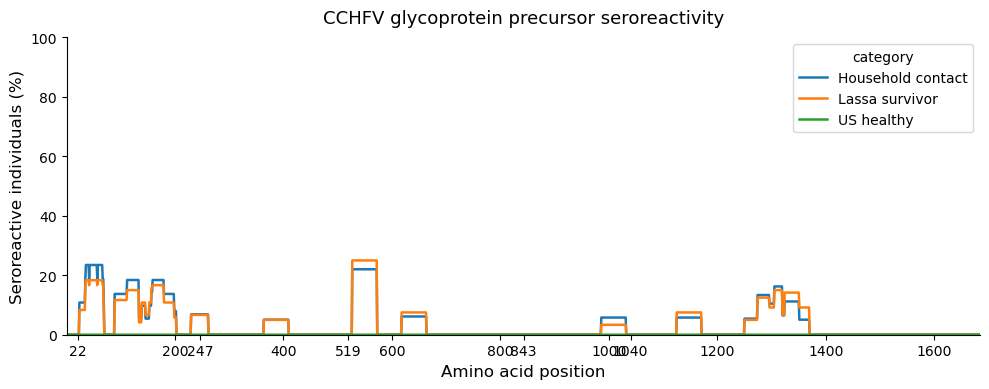

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(10, 4))

sns.lineplot(
    data= position_summary, 
    x='position', 
    y='pct_seroreactive', 
    hue='category', 
    linewidth=1.8, 
    ax=ax
)

ax.set_xlabel('Amino acid position', fontsize=12)
ax.set_ylabel('Seroreactive individuals (%)', fontsize=12)
ax.set_xlim(1, len(ref)) #minimum and maximum position
ax.set_ylim(0,  100)

ax.spines['top'].set_visible(False)
ax.spines["right"].set_visible(False)

ax.set_xticks([22, 200, 247, 400, 519, 600, 800, 843, 1000, 1040, 1200, 1400, 1600])

plt.title('CCHFV glycoprotein precursor seroreactivity', y=1.02, fontsize=13)
plt.tight_layout()
plt.rcParams['svg.fonttype'] = 'none'
plt.savefig('CCHFV_glycoprotein_reactivity.svg', format='svg')
plt.show()

### any individuals with more than 1 peptide reactive beyond AA200? 

In [35]:
cchfv.loc[(cchfv['individual'] == 'S-456_SA2_E4') & (cchfv['z_score'] > 3)]

,peptide,individual,z_score,rpk,sequence,species,genus,family,protein_std,accession,cohort,category,reactive
310425,XPD10970.1|glycoprotein|Orthonairovirus_haemor...,S-456_SA2_E4,3.383151,3.801053,LTICVVSTSAVEMENLPAGTWEREEDLTNFCHQECQVTETECLCPY,Orthonairovirus haemorrhagiae,Orthonairovirus,Nairoviridae,glycoprotein,XPD10970.1,SL,Lassa survivor,True
310585,QRG45927.1|precursor|Orthonairovirus_haemorrha...,S-456_SA2_E4,7.697935,17.342304,VTTTKEDPTTVSPLIVKDSTAVISTRNITNHSTPGQIGPTTPGAIS,Orthonairovirus haemorrhagiae,Orthonairovirus,Nairoviridae,glycoprotein,QRG45927.1,SL,Lassa survivor,True


In [36]:
cchfv.loc[(cchfv['individual'] == 'C-511-1_3_I8') & (cchfv['z_score'] > 3)]

,peptide,individual,z_score,rpk,sequence,species,genus,family,protein_std,accession,cohort,category,reactive
266602,XMH26463.1|precursor|Orthonairovirus_haemorrha...,C-511-1_3_I8,4.582757,4.657328,GNLLKGDKINGNSFHKIEPNLNTSWMSWDGCDLDYYCNMGDWPSCT,Orthonairovirus haemorrhagiae,Orthonairovirus,Nairoviridae,glycoprotein,XMH26463.1,SL,Household contact,True
266622,XKB88840.1|precursor|Orthonairovirus_haemorrha...,C-511-1_3_I8,3.221633,2.686920,LPPEIITLHPKIEEGFFDLMHVQRVLSASTVCKLQSCTHGVPGDLQ,Orthonairovirus haemorrhagiae,Orthonairovirus,Nairoviridae,glycoprotein,XKB88840.1,SL,Household contact,True
266649,WQM42206.1|precursor|Orthonairovirus_haemorrha...,C-511-1_3_I8,3.889781,2.866048,EASTIPQDTHHTARGLLSVTVTKPEEVPTPTGSKKASMETSSPHLV,Orthonairovirus haemorrhagiae,Orthonairovirus,Nairoviridae,glycoprotein,WQM42206.1,SL,Household contact,True
266663,WHU52062.1|nucleoprotein|Orthonairovirus_haemo...,C-511-1_3_I8,7.505411,13.792856,FGTIPVANPDDAAQGSGHTKSILNLRTSADTNNPCAKTIVKLFEVQ,Orthonairovirus haemorrhagiae,Orthonairovirus,Nairoviridae,nucleoprotein,WHU52062.1,SL,Household contact,True


In [37]:
cchfv.loc[(cchfv['individual'] == 'C-504-2_5_C1') & (cchfv['z_score'] > 3)].peptide.to_list()

['XPD10970.1|glycoprotein|Orthonairovirus_haemorrhagiae|isolate=372-ARM-TI-2022|tick|Armenia|2022|segment=M|strain=?|tile_44']

In [38]:
cchfv_gp = cchfv.loc[cchfv['protein_std'] == 'glycoprotein']

In [39]:
cchfv_gp['tile_num'] = cchfv_gp['peptide'].str.rsplit("_", n=1).str[1]

/tmp/ipykernel_3349119/1961158537.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  cchfv_gp['tile_num'] = cchfv_gp['peptide'].str.rsplit("_", n=1).str[1]


In [40]:
cchfv_gp_keep = cchfv_gp[cchfv_gp['tile_num'].astype(int) > 22]

In [41]:
cchfv_gp_keep.groupby(['individual', 'tile_num'])['reactive'].sum().reset_index(name='n_reactive').sort_values(by='n_reactive', ascending=False).head(10)

,individual,tile_num,n_reactive
772,C-183-2_3_A8,56,1
3169,S-138_SA1_D3,28,1
766,C-183-1_1_F4,58,1
763,C-183-1_1_F4,50,1
760,C-183-1_1_F4,24,1
3186,S-140_SA1_E3,44,1
3192,S-141_SA1_D7,24,1
740,C-181-1_1_F3,56,1
3198,S-141_SA1_D7,58,1
3199,S-141_SA1_D7,59,1


In [42]:
cchfv['protein_std'].unique()

array(['polymerase', 'glycoprotein', 'nucleoprotein', 'polyprotein'],
      dtype=object)

In [43]:
cchfv_np = cchfv.loc[cchfv['protein_std'] == 'nucleoprotein']

cchfv_np.groupby(['individual', 'peptide'])['reactive'].sum().reset_index(name='n_reactive').sort_values(by='n_reactive', ascending=False).head(10)

,individual,peptide,n_reactive
5,C-110-3_2_E6,WHU52062.1|nucleoprotein|Orthonairovirus_haemo...,1
405,S-147_SA1_E6,WHU52062.1|nucleoprotein|Orthonairovirus_haemo...,1
28,C-122-2_3_B8,WHU52062.1|nucleoprotein|Orthonairovirus_haemo...,1
453,S-468_SA2_I7,WHU52062.1|nucleoprotein|Orthonairovirus_haemo...,1
410,S-168_SA2_B3,WHU52062.1|nucleoprotein|Orthonairovirus_haemo...,1
414,S-182_SA4_D9,WHU52062.1|nucleoprotein|Orthonairovirus_haemo...,1
419,S-187_SA1_F8,WHU52062.1|nucleoprotein|Orthonairovirus_haemo...,1
364,S-104_SA1_A3,WHU52062.1|nucleoprotein|Orthonairovirus_haemo...,1
368,S-109_SA1_B1,WHU52062.1|nucleoprotein|Orthonairovirus_haemo...,1
261,C-509-2_3_G7,WHU52062.1|nucleoprotein|Orthonairovirus_haemo...,1


### keeping individuals with reactivity beyond AA200 

In [44]:
keep =(reactive_residues[reactive_residues['position'] > 400])

In [45]:
keep['individual'].unique()

array(['C-109-3_4_E7', 'C-111-3_3_I6', 'C-112-1_3_B3', 'C-130-2_3_C3',
       'C-135-2_1_D2', 'C-140-1_1_A7', 'C-144-2_2_B5', 'C-147-2_1_F5',
       'C-150-2_1_H3', 'C-183-1_1_F4', 'C-192-3_1_D3', 'C-434-3_5_E2',
       'C-438-1_3_A4', 'C-441-3_2_G4', 'C-444-2_2_E4', 'C-464-3_3_F9',
       'C-467-3_2_D5', 'C-470-3_2_F8', 'C-475-2_2_F5', 'C-483-1_1_D9',
       'C-484-2_3_D4', 'C-485-3_2_H3', 'C-489-2_3_D5', 'C-499-3_1_B2',
       'C-505-2_4_C2', 'C-508-2_4_A8', 'S-107_SA1_A9', 'S-113_SA1_B4',
       'S-114_SA1_B5', 'S-115_SA1_A5', 'S-125_SA1_C3', 'S-126_SA1_C4',
       'S-148_SA1_E7', 'S-186_SA1_G3', 'S-463_SA2_F8', 'S-488_SA1_H2',
       'S-502_SA4_I1', 'S-509_SA3_H6', 'C-109-1_5_B3', 'C-114-3_3_B6',
       'C-122-2_3_B8', 'C-137-3_2_A9', 'C-139-2_6_D5', 'C-145-2_2_A6',
       'C-145-3_1_E4', 'C-148-3_1_G3', 'C-191-3_1_A3', 'C-449-3_7_E4',
       'C-462-2_2_D4', 'C-462-3_2_I6', 'C-465-3_5_G8', 'C-467-1_2_D6',
       'C-472-3_2_E9', 'C-475-1_3_G6', 'C-497-3_1_A5', 'C-499-1_2_C2',
      

In [46]:
edges = [0, 400, 600, 700, 900, reactive_residues['position'].max() + 1]

labels = ['1-400', '400-600', '600-700', '700-900', '900+']

reactive_residues['region'] = pd.cut(reactive_residues['position'], bins=edges, labels=labels, right=False)
#pd.cut() sorts into bins/intervals

In [47]:
region_matrix= pd.crosstab(reactive_residues['individual'], reactive_residues['region']) >0

n_regions = region_matrix.sum(axis=1)
n_regions.value_counts().sort_index()

1    167
2    108
3     24
4      2
Name: count, dtype: int64

In [48]:
region_matrix.loc['C-447-3_1_C8']

region
1-400       True
400-600    False
600-700    False
900+       False
Name: C-447-3_1_C8, dtype: bool

In [49]:
region_matrix.loc['S-126_SA1_C4']

region
1-400      True
400-600    True
600-700    True
900+       True
Name: S-126_SA1_C4, dtype: bool

In [50]:
region_matrix.loc['S-148_SA1_E7']

region
1-400       True
400-600     True
600-700    False
900+        True
Name: S-148_SA1_E7, dtype: bool

In [51]:
multi = region_matrix[n_regions >=3]

In [52]:
multi

region,1-400,400-600,600-700,900+
individual,,,,
C-112-1_3_B3,True,True,False,True
C-130-2_3_C3,True,True,False,True
C-137-3_2_A9,True,True,False,True
C-183-2_3_A8,True,True,False,True
C-446-2_2_E7,True,True,False,True
C-449-1_3_F3,True,True,False,True
C-462-2_2_D4,True,True,True,False
C-472-2_2_G1,True,True,False,True
C-475-1_3_G6,True,True,False,True
